# Prévision de l'inflation mensuelle au Maroc par régression linéaire

**Données :** IPC par grandes divisions, mensuel, base 100 = 2017 (Haut-Commissariat au Plan, HCP) — janvier 2017 à septembre 2026.

**Question :** peut-on prévoir l'inflation mensuelle générale du mois *t* à partir des inflations passées (t-1, t-2) de l'alimentation, du non-alimentaire et de l'indice général, et de la saisonnalité ?

**Plan du notebook**
0. Configuration et imports
1. Chargement et nettoyage des données
2. Ingénierie des variables (taux d'inflation, retards, saison)
3. Analyse exploratoire
4. Découpage chronologique et modélisation
5. Évaluation sur le jeu de test
6. Interprétation et limites

## Étape 0 — Configuration et imports

In [24]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Chemins relatifs à la racine du projet (le notebook est dans notebooks/)
FILE_PATH = "../data/raw/ipc_mensuel_base100_2017.xlsx"
FIG_DIR = "../figures"
os.makedirs(FIG_DIR, exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"font.size": 11, "figure.dpi": 100, "savefig.dpi": 300})

def save_fig(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}", bbox_inches="tight")

In [25]:
from google.colab import drive

# 1. Connexion au Google Drive
drive.mount('/content/drive')

# 2. Chemin exact vers votre fichier Excel dans Drive
FILE_PATH = '/content/drive/MyDrive/CC PARTIE B/IPC par grandes divisions - mensuel (Base 100 _ 2017).xlsx'

print("Connexion établie. Chemin du fichier configuré sur :", FILE_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Connexion établie. Chemin du fichier configuré sur : /content/drive/MyDrive/CC PARTIE B/IPC par grandes divisions - mensuel (Base 100 _ 2017).xlsx


## Étape 1 — Chargement et nettoyage

Le fichier du HCP contient des lignes vides et un en-tête (ligne 24), puis les données **du plus récent au plus ancien**, et enfin une note de source en bas. On détecte la ligne d'en-tête automatiquement plutôt que de coder un `skiprows` fragile.

In [26]:
import os

# Verification of the file path before loading
if not os.path.exists(FILE_PATH):
    print(f"[!] Warning: The file was not found at {FILE_PATH}")
    print(f"Current working directory: {os.getcwd()}")
    print("Available files in current directory:", os.listdir('.'))
else:
    raw = pd.read_excel(FILE_PATH, header=None)

    # Repère la ligne d'en-tête (celle qui contient "Mois")
    header_row = raw.index[raw.apply(lambda r: r.astype(str).str.strip().eq("Mois").any(), axis=1)][0]
    df = raw.iloc[header_row + 1:, 1:5].copy()
    df.columns = ["Mois", "Alimentation", "Non_Alimentaire", "Indice_General"]

    # Dates au format AAAA/MM ; les notes de bas de page deviennent NaT et sont supprimées
    df["Date"] = pd.to_datetime(df["Mois"].astype(str).str.strip().str.replace("/", "-"),
                                format="%Y-%m", errors="coerce")
    df = df.dropna(subset=["Date"]).copy()

    for col in ["Alimentation", "Non_Alimentaire", "Indice_General"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df = (df.drop(columns="Mois").dropna()
            .sort_values("Date").reset_index(drop=True)[["Date", "Alimentation", "Non_Alimentaire", "Indice_General"]])

    print(f"Dimensions : {df.shape[0]} mois, {df.shape[1]} colonnes")
    print(f"Période : {df['Date'].min():%Y-%m} -> {df['Date'].max():%Y-%m}")
    print(f"Valeurs manquantes : {df.isna().sum().sum()} | Doublons de date : {df['Date'].duplicated().sum()}")

    # Contrôle de continuité : aucun mois manquant
    attendu = pd.date_range(df["Date"].min(), df["Date"].max(), freq="MS")
    print(f"Mois manquants : {len(attendu.difference(df['Date']))}")
    df.head()

Dimensions : 117 mois, 4 colonnes
Période : 2017-01 -> 2026-09
Valeurs manquantes : 0 | Doublons de date : 0
Mois manquants : 0


## Étape 2 — Ingénierie des variables

- **Inflation mensuelle** = variation en % de l'indice par rapport au mois précédent (pour les trois séries).
- **Retards t-1 et t-2** : seules des informations *passées* servent à prévoir le mois *t* (pas de fuite de données).
- **Mois (1–12)** : capture la saisonnalité.

In [27]:
df["Inflation_General"] = df["Indice_General"].pct_change() * 100
df["Inflation_Alim"]    = df["Alimentation"].pct_change() * 100
df["Inflation_NonAlim"] = df["Non_Alimentaire"].pct_change() * 100

for lag in [1, 2]:
    df[f"Inf_Gen_lag{lag}"]    = df["Inflation_General"].shift(lag)
    df[f"Inf_Alim_lag{lag}"]   = df["Inflation_Alim"].shift(lag)
    df[f"Inf_NonAlim_lag{lag}"] = df["Inflation_NonAlim"].shift(lag)

df["Mois_Num"] = df["Date"].dt.month

# 3 premières lignes perdues (1 pour pct_change + 2 pour les retards)
df_model = df.dropna().reset_index(drop=True)
print(f"Observations exploitables : {len(df_model)} mois "
      f"({df_model['Date'].min():%Y-%m} -> {df_model['Date'].max():%Y-%m})")
df_model[["Date", "Inflation_General", "Inf_Gen_lag1", "Inf_Alim_lag1", "Inf_NonAlim_lag1", "Mois_Num"]].head()

Observations exploitables : 114 mois (2017-04 -> 2026-09)


,Date,Inflation_General,Inf_Gen_lag1,Inf_Alim_lag1,Inf_NonAlim_lag1,Mois_Num
0,2017-04-01,0.000000,-0.201005,-0.607287,0.0000,4
1,2017-05-01,0.402820,0.000000,0.305499,-0.1000,5
2,2017-06-01,0.300903,0.402820,1.116751,-0.1001,6
3,2017-07-01,-0.500000,0.300903,0.803213,0.0000,7
4,2017-08-01,0.301508,-0.500000,-1.095618,-0.1002,8


## Étape 3 — Analyse exploratoire

In [28]:
print(df_model[["Inflation_General", "Inflation_Alim", "Inflation_NonAlim"]].describe().round(3))
print("\nPrécision des indices : 1 décimale -> une variation mensuelle est quantifiée par pas d'environ "
      f"{0.1 / df['Indice_General'].mean() * 100:.2f} point de %.")

       Inflation_General  Inflation_Alim  Inflation_NonAlim
count            114.000         114.000            114.000
mean               0.174           0.245              0.128
std                0.562           1.246              0.270
min               -1.001          -2.445             -0.684
25%               -0.195          -0.597              0.000
50%                0.193           0.215              0.097
75%                0.494           0.920              0.199
max                1.791           3.915              1.235

Précision des indices : 1 décimale -> une variation mensuelle est quantifiée par pas d'environ 0.09 point de %.


**Figure 1 — Évolution des indices bruts (base 100 = 2017)**

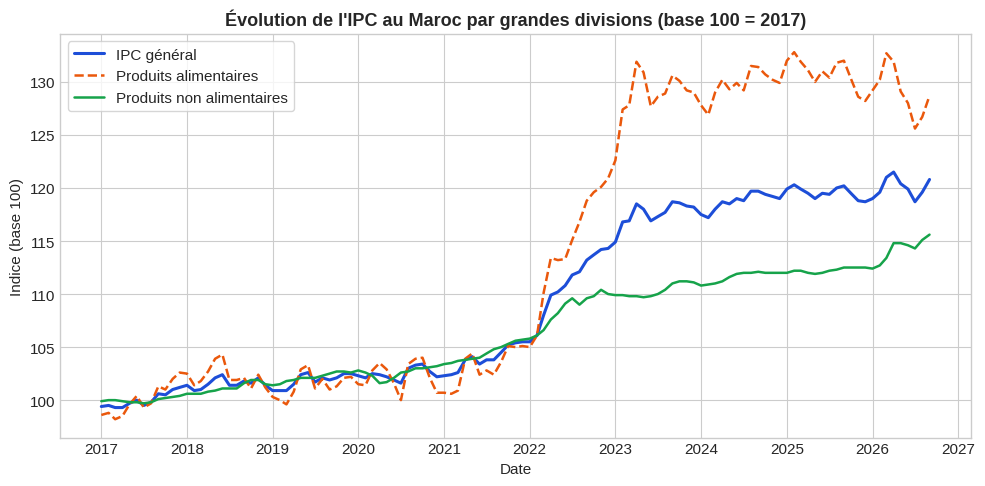

In [29]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df["Date"], df["Indice_General"], label="IPC général", color="#1d4ed8", linewidth=2.2)
ax.plot(df["Date"], df["Alimentation"], label="Produits alimentaires", color="#ea580c", linewidth=1.8, linestyle="--")
ax.plot(df["Date"], df["Non_Alimentaire"], label="Produits non alimentaires", color="#16a34a", linewidth=1.8)
ax.set_title("Évolution de l'IPC au Maroc par grandes divisions (base 100 = 2017)", fontsize=13, fontweight="bold")
ax.set_xlabel("Date"); ax.set_ylabel("Indice (base 100)")
ax.legend(frameon=True, facecolor="white")
plt.tight_layout(); save_fig(fig, "fig1_evolution_ipc.png"); plt.show()

**Figure 2 — Inflation mensuelle (%)**

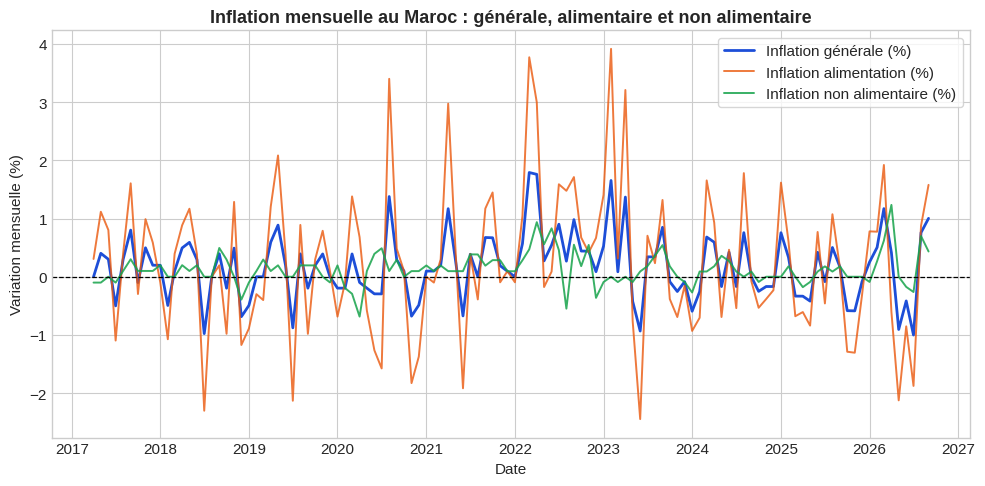

In [30]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df_model["Date"], df_model["Inflation_General"], label="Inflation générale (%)", color="#1d4ed8", linewidth=2)
ax.plot(df_model["Date"], df_model["Inflation_Alim"], label="Inflation alimentation (%)", color="#ea580c", alpha=0.8, linewidth=1.4)
ax.plot(df_model["Date"], df_model["Inflation_NonAlim"], label="Inflation non alimentaire (%)", color="#16a34a", alpha=0.85, linewidth=1.4)
ax.axhline(0, color="black", linestyle="--", linewidth=0.9)
ax.set_title("Inflation mensuelle au Maroc : générale, alimentaire et non alimentaire", fontsize=13, fontweight="bold")
ax.set_xlabel("Date"); ax.set_ylabel("Variation mensuelle (%)")
ax.legend(frameon=True, facecolor="white")
plt.tight_layout(); save_fig(fig, "fig2_volatilite_inflation.png"); plt.show()

**Figure 3 — Saisonnalité de l'inflation générale**

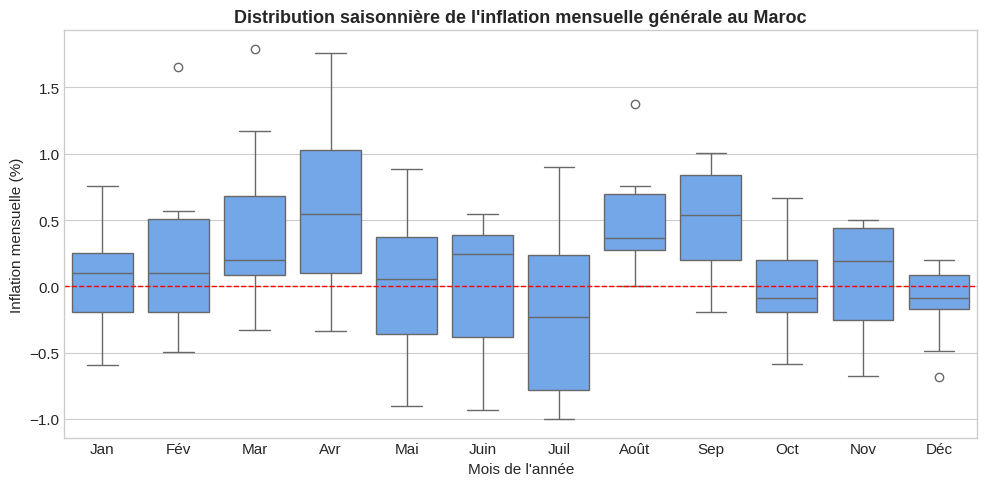

In [31]:
mois_labels = ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Août", "Sep", "Oct", "Nov", "Déc"]
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(x="Mois_Num", y="Inflation_General", data=df_model, color="#60a5fa", ax=ax)
ax.set_xticks(range(12)); ax.set_xticklabels(mois_labels)
ax.axhline(0, color="red", linestyle="--", linewidth=1)
ax.set_title("Distribution saisonnière de l'inflation mensuelle générale au Maroc", fontsize=13, fontweight="bold")
ax.set_xlabel("Mois de l'année"); ax.set_ylabel("Inflation mensuelle (%)")
plt.tight_layout(); save_fig(fig, "fig3_saisonnalite_inflation.png"); plt.show()

## Étape 4 — Découpage chronologique et modélisation

Découpage **strictement chronologique** 80 % / 20 % (jamais aléatoire pour une série temporelle). Le prétraitement (standardisation, encodage du mois) est inclus dans le `Pipeline`, donc ajusté sur le train uniquement. Le paramètre `alpha` de Ridge est choisi par `TimeSeriesSplit` **sur le train seulement**.

In [32]:
features_num = ["Inf_Gen_lag1", "Inf_Gen_lag2", "Inf_Alim_lag1", "Inf_Alim_lag2",
                "Inf_NonAlim_lag1", "Inf_NonAlim_lag2"]
features_cat = ["Mois_Num"]
target = "Inflation_General"

split_idx = int(len(df_model) * 0.80)
train_df = df_model.iloc[:split_idx].copy()
test_df  = df_model.iloc[split_idx:].copy()

X_train, y_train = train_df[features_num + features_cat], train_df[target]
X_test,  y_test  = test_df[features_num + features_cat],  test_df[target]

print(f"Train : {len(train_df)} mois ({train_df['Date'].min():%Y-%m} -> {train_df['Date'].max():%Y-%m})")
print(f"Test  : {len(test_df)} mois ({test_df['Date'].min():%Y-%m} -> {test_df['Date'].max():%Y-%m})")
print("Mois présents dans le train :", sorted(int(m) for m in train_df["Mois_Num"].unique()))

Train : 91 mois (2017-04 -> 2024-10)
Test  : 23 mois (2024-11 -> 2026-09)
Mois présents dans le train : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


In [33]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), features_num),
    ("cat", OneHotEncoder(drop="first", sparse_output=False), features_cat),
])

# Modèle 1 : MCO
pipeline_ols = Pipeline([("preprocessor", preprocessor), ("regressor", LinearRegression())])
pipeline_ols.fit(X_train, y_train)

# Modèle 2 : Ridge, alpha choisi par validation croisée temporelle (train uniquement)
pipeline_ridge = Pipeline([("preprocessor", preprocessor), ("regressor", Ridge(random_state=RANDOM_SEED))])
grid_ridge = GridSearchCV(
    pipeline_ridge,
    param_grid={"regressor__alpha": [0.1, 1.0, 10.0, 50.0, 100.0, 300.0, 1000.0, 3000.0]},
    cv=TimeSeriesSplit(n_splits=5),
    scoring="neg_root_mean_squared_error",
)
grid_ridge.fit(X_train, y_train)
print("Meilleur alpha Ridge :", grid_ridge.best_params_["regressor__alpha"])
print(f"RMSE de validation croisée (train) : {-grid_ridge.best_score_:.4f}")

Meilleur alpha Ridge : 100.0
RMSE de validation croisée (train) : 0.5626


## Étape 5 — Évaluation sur le jeu de test

In [34]:
y_pred_naive = test_df["Inf_Gen_lag1"].values            # persistance : y(t) = y(t-1)
y_pred_mean  = np.full(len(test_df), y_train.mean())     # moyenne du train
y_pred_ols   = pipeline_ols.predict(X_test)
y_pred_ridge = grid_ridge.best_estimator_.predict(X_test)

def get_metrics(y_true, y_pred, label):
    return {"Modèle": label,
            "RMSE (%)": round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 4),
            "MAE (%)":  round(float(mean_absolute_error(y_true, y_pred)), 4),
            "R2":       round(float(r2_score(y_true, y_pred)), 4)}

results_df = pd.DataFrame([
    get_metrics(y_test, y_pred_mean,  "Référence : moyenne du train"),
    get_metrics(y_test, y_pred_naive, "Référence naïve (persistance)"),
    get_metrics(y_test, y_pred_ols,   "Régression linéaire (MCO)"),
    get_metrics(y_test, y_pred_ridge, f"Ridge (alpha={grid_ridge.best_params_['regressor__alpha']})"),
])
results_df

,Modèle,RMSE (%),MAE (%),R2
0,Référence : moyenne du train,0.5968,0.5060,-0.0693
1,Référence naïve (persistance),0.6720,0.5266,-0.3558
2,Régression linéaire (MCO),0.6579,0.5339,-0.2996
3,Ridge (alpha=100.0),0.5929,0.4925,-0.0555


**Figure 4 — Prévisions sur le jeu de test**

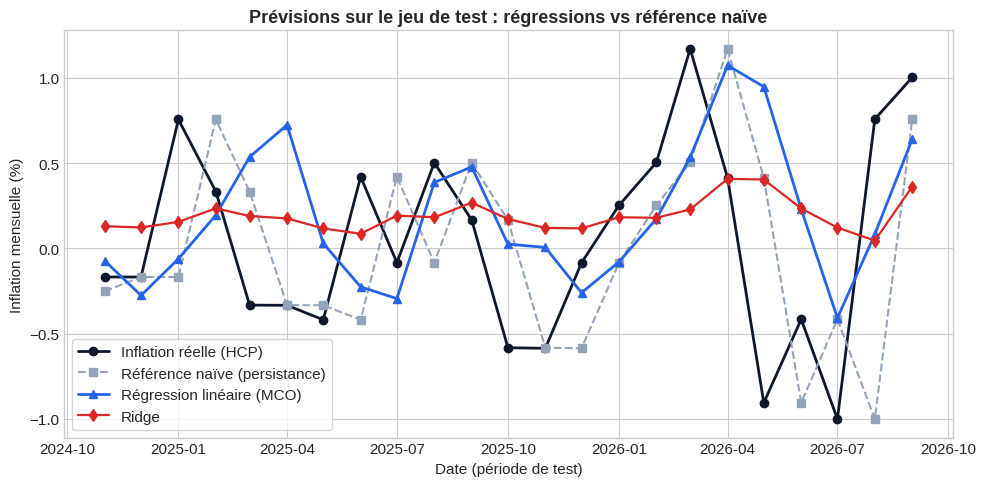

In [35]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(test_df["Date"], y_test, label="Inflation réelle (HCP)", color="#0f172a", marker="o", linewidth=2)
ax.plot(test_df["Date"], y_pred_naive, label="Référence naïve (persistance)", color="#94a3b8", linestyle="--", marker="s")
ax.plot(test_df["Date"], y_pred_ols, label="Régression linéaire (MCO)", color="#2563eb", marker="^", linewidth=2)
ax.plot(test_df["Date"], y_pred_ridge, label="Ridge", color="#dc2626", marker="d", linewidth=1.6)
ax.set_title("Prévisions sur le jeu de test : régressions vs référence naïve", fontsize=13, fontweight="bold")
ax.set_xlabel("Date (période de test)"); ax.set_ylabel("Inflation mensuelle (%)")
ax.legend(frameon=True, facecolor="white")
plt.tight_layout(); save_fig(fig, "fig4_resultats_predictions.png"); plt.show()

**Figure 5 — Résidus du modèle linéaire (réel − prédit)**

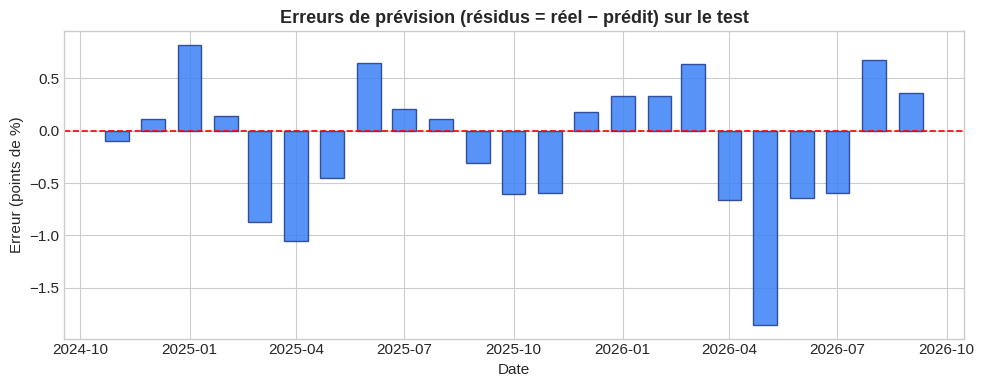

Moyenne des résidus : -0.1386 | écart-type : 0.6432


In [36]:
residuals = y_test.values - y_pred_ols
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(test_df["Date"], residuals, width=20, color="#3b82f6", edgecolor="#1e3a8a", alpha=0.85)
ax.axhline(0, color="red", linestyle="--", linewidth=1.2)
ax.set_title("Erreurs de prévision (résidus = réel − prédit) sur le test", fontsize=13, fontweight="bold")
ax.set_xlabel("Date"); ax.set_ylabel("Erreur (points de %)")
plt.tight_layout(); save_fig(fig, "fig5_analyse_residus.png"); plt.show()
print(f"Moyenne des résidus : {residuals.mean():.4f} | écart-type : {residuals.std():.4f}")

**Figure 6 — Coefficients du modèle MCO (variables standardisées)**

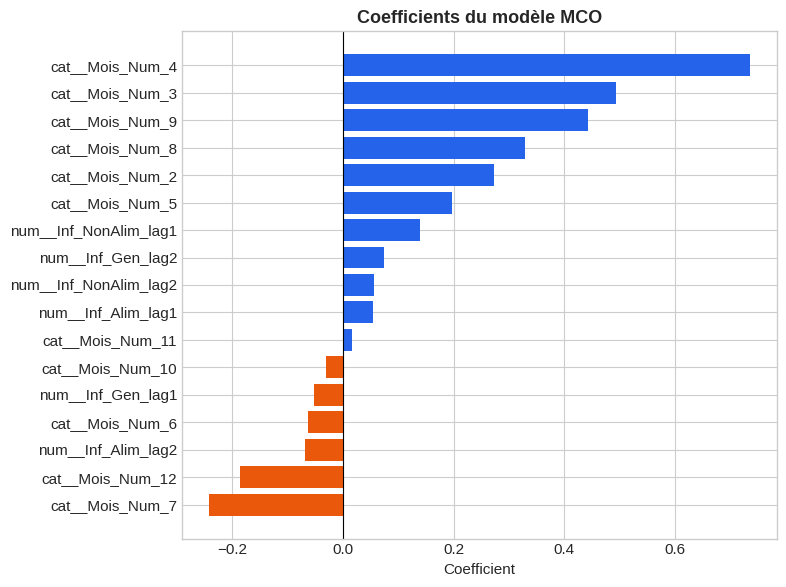

In [37]:
names = pipeline_ols.named_steps["preprocessor"].get_feature_names_out()
coefs = pd.Series(pipeline_ols.named_steps["regressor"].coef_, index=names).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(coefs.index, coefs.values, color=np.where(coefs.values >= 0, "#2563eb", "#ea580c"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Coefficients du modèle MCO", fontsize=13, fontweight="bold")
ax.set_xlabel("Coefficient")
plt.tight_layout(); save_fig(fig, "fig6_coefficients.png"); plt.show()

## Étape 6 — Interprétation et limites

In [38]:
best = results_df.loc[results_df["RMSE (%)"].idxmin(), "Modèle"]
naive_rmse = results_df.loc[results_df["Modèle"].str.contains("naïve"), "RMSE (%)"].iloc[0]
ols_rmse   = results_df.loc[results_df["Modèle"].str.contains("MCO"), "RMSE (%)"].iloc[0]
print(f"Meilleur modèle (RMSE) : {best}")
print(f"RMSE naïf = {naive_rmse} | RMSE MCO = {ols_rmse} | gain relatif MCO vs naïf = {(1 - ols_rmse / naive_rmse) * 100:.1f} %")
print("R2 < 0 pour un modèle = il prédit moins bien que la simple moyenne du test.")

Meilleur modèle (RMSE) : Ridge (alpha=100.0)
RMSE naïf = 0.672 | RMSE MCO = 0.6579 | gain relatif MCO vs naïf = 2.1 %
R2 < 0 pour un modèle = il prédit moins bien que la simple moyenne du test.


**Points à discuter dans le rapport**

- **Résultat principal** : tous les modèles ont un R² négatif sur le test ; seule la régularisation forte (Ridge, qui tend vers la moyenne) fait légèrement mieux que la persistance. Les inflations passées prédisent donc très peu l'inflation mensuelle du HCP : c'est un résultat à présenter honnêtement, pas un échec du code.
- **Petit échantillon** : ~23 mois de test seulement ; les métriques (surtout R²) sont instables et un seul choc (ex. hausse alimentaire) peut dominer le RMSE.
- **Indices arrondis à 1 décimale** : l'inflation mensuelle calculée est quantifiée par pas d'environ 0,08 point ; une partie de l'erreur est du bruit d'arrondi, pas du signal.
- **Ne pas conclure sur un seul score** : la référence naïve (persistance) est difficile à battre sur une inflation mensuelle ; comparer toujours à elle.
- **Pistes d'amélioration** : prévoir le glissement annuel plutôt que mensuel, ajouter des variables exogènes (prix du pétrole, taux de change, calendrier du Ramadan/Aïd), valider par fenêtre glissante.